# News Topic Classification from Headlines

**NLP Project - Option 3** | Section 1 | Group 2

| Role | Name | Student ID |
|---|---|---|
| Team leader | Mohammed Saeed Alamodi | 2240009007 |
| Member 2 | Abdulaziz Mohammed Alkhlawi | 2240006095 |
| Member 3 | Jaber Saleh Alsaikhan | 2240006539 |

Input: one English news headline. Output: World, Sports, Business or Sci/Tech.

**Question:** If only the headline is available, is a pretrained sentence-embedding classifier better than TF-IDF logistic regression at separating Business and Sci/Tech headlines?

We compare:
- Method 1: TF-IDF + logistic regression
- Method 2: all-MiniLM-L6-v2 sentence embeddings + logistic regression

The notebook was made for Google Colab (it also runs in Jupyter). A GPU runtime makes Method 2 faster.

## Setup

In [1]:
!pip install -q sentence-transformers kagglehub


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import html
import re
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import sklearn
import sentence_transformers
from threadpoolctl import threadpool_limits
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sentence_transformers import SentenceTransformer

SEED = 42
np.random.seed(SEED)
threadpool_limits(4)  

LABELS = ["World", "Sports", "Business", "Sci/Tech"]
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)


## Data

AG News from Kaggle (amananandrai/ag-news-classification-dataset). We only use the Title column and the class label.

In [3]:
if not os.path.exists("data/train.csv"):
    import kagglehub
    path = kagglehub.dataset_download("amananandrai/ag-news-classification-dataset")
    pd.read_csv(f"{path}/train.csv").to_csv("data/train.csv", index=False)
    pd.read_csv(f"{path}/test.csv").to_csv("data/test.csv", index=False)

train_raw = pd.read_csv("data/train.csv", keep_default_na=False)
test_raw = pd.read_csv("data/test.csv", keep_default_na=False)
train_raw["label"] = train_raw["Class Index"] - 1
test_raw["label"] = test_raw["Class Index"] - 1

counts = pd.DataFrame({"train": train_raw["label"].value_counts().sort_index(),
                       "test": test_raw["label"].value_counts().sort_index()})
counts.index = LABELS
print(counts)
print("average words per title:", round(train_raw["Title"].str.split().str.len().mean(), 1))
train_raw[["Title", "label"]].head()

          train  test
World     30000  1900
Sports    30000  1900
Business  30000  1900
Sci/Tech  30000  1900


average words per title: 6.8


,Title,label
0,Wall St. Bears Claw Back Into the Black (Reuters),2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters),2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


### Cleaning

Problems we found in the titles:
1. HTML leftovers like `#39;` and `&lt;` -> unescaped.
2. Source tags `(Reuters)`, `(AP)`, `(AFP)` at the end of titles -> removed because they give away the label.
3. Duplicates -> repeats stay in the same split, test titles that also appear in training are removed.
4. Titles with more than one label -> removed from training (label noise).

In [4]:
def clean_title(text):
    text = re.sub(r"(^|\s)(#\d+|quot|amp|lt|gt);", lambda m: "&" + m.group(2) + ";", text)
    text = html.unescape(html.unescape(text))
    text = text.replace("\\$", "$")
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\((Reuters|AP|AFP)\)", " ", text)
    return re.sub(r"\s+", " ", text).strip()


has_html = train_raw["Title"].str.contains(r"#\d+;|&[a-z]+;|quot;|amp;", regex=True)
has_tag = train_raw["Title"].str.contains(r"\((?:Reuters|AP|AFP)\)", regex=True)
print("titles with HTML leftovers:", has_html.sum())
print("titles with (Reuters)/(AP)/(AFP):", has_tag.sum())
afp = train_raw[train_raw["Title"].str.contains(r"\(AFP\)", regex=True)]
print("share of (AFP) titles that are World:", round((afp["label"] == 0).mean(), 2))

for df in (train_raw, test_raw):
    df["text"] = df["Title"].apply(clean_title)
    df["key"] = df["text"].str.lower()

pd.DataFrame({"before": train_raw.loc[has_html | has_tag, "Title"].head(5).values,
              "after": train_raw.loc[has_html | has_tag, "text"].head(5).values})

titles with HTML leftovers: 12960
titles with (Reuters)/(AP)/(AFP): 13878
share of (AFP) titles that are World: 0.77


,before,after
0,Wall St. Bears Claw Back Into the Black (Reuters),Wall St. Bears Claw Back Into the Black
1,Carlyle Looks Toward Commercial Aerospace (Reu...,Carlyle Looks Toward Commercial Aerospace
2,Oil and Economy Cloud Stocks' Outlook (Reuters),Oil and Economy Cloud Stocks' Outlook
3,Iraq Halts Oil Exports from Main Southern Pipe...,Iraq Halts Oil Exports from Main Southern Pipe...
4,"Oil prices soar to all-time record, posing new...","Oil prices soar to all-time record, posing new..."


In [5]:
print("repeated training titles:", len(train_raw) - train_raw["key"].nunique())

labels_per_title = train_raw.groupby("key")["label"].nunique()
conflicts = labels_per_title[labels_per_title > 1].index
print("titles with more than one label:", len(conflicts))
train_clean = train_raw[~train_raw["key"].isin(conflicts)]

in_train = test_raw["key"].isin(train_raw["key"])
print("test titles also in training:", in_train.sum())
test = test_raw[~in_train].reset_index(drop=True)

# split unique titles so that repeats end up in the same split
unique_titles = train_clean.drop_duplicates("key")
_, dev_keys = train_test_split(unique_titles["key"], test_size=0.1, stratify=unique_titles["label"],
                               random_state=SEED)
is_dev = train_clean["key"].isin(dev_keys)
train = train_clean[~is_dev].reset_index(drop=True)
dev = train_clean[is_dev].reset_index(drop=True)

print("overlap train/dev:", len(set(train["key"]) & set(dev["key"])),
      "| train/test:", len(set(train["key"]) & set(test["key"])))
print("train:", len(train), "| dev:", len(dev), "| test:", len(test))

repeated training titles: 9980
titles with more than one label: 1088
test titles also in training: 1131


overlap train/dev: 0 | train/test: 0
train: 105695 | dev: 11724 | test: 6469


## Method 1: TF-IDF + Logistic Regression

We choose the n-gram range and C on the development set (macro F1).

In [6]:
results = []
for ngram in [(1, 1), (1, 2)]:
    vec = TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True)
    X_train = vec.fit_transform(train["text"])
    X_dev = vec.transform(dev["text"])
    for C in [0.5, 1, 2, 4, 8, 16]:
        clf = LogisticRegression(C=C, solver="saga", max_iter=2000, random_state=SEED)
        clf.fit(X_train, train["label"])
        pred = clf.predict(X_dev)
        results.append({"ngram": ngram, "C": C, "dev_acc": accuracy_score(dev["label"], pred),
                        "dev_macro_f1": f1_score(dev["label"], pred, average="macro")})

tfidf_dev = pd.DataFrame(results)
best1 = tfidf_dev.loc[tfidf_dev["dev_macro_f1"].idxmax()]
print("best:", best1["ngram"], "C =", best1["C"])
tfidf_dev.round(4)

best: (1, 2) C = 2.0


,ngram,C,dev_acc,dev_macro_f1
0,"(1, 1)",0.5,0.8651,0.8644
1,"(1, 1)",1.0,0.8687,0.8680
2,"(1, 1)",2.0,0.8713,0.8706
3,"(1, 1)",4.0,0.8708,0.8702
4,"(1, 1)",8.0,0.8660,0.8654
5,"(1, 1)",16.0,0.8604,0.8598
6,"(1, 2)",0.5,0.8662,0.8654
7,"(1, 2)",1.0,0.8731,0.8724
8,"(1, 2)",2.0,0.8767,0.8762
9,"(1, 2)",4.0,0.8753,0.8747


In [7]:
tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=best1["ngram"], min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(C=best1["C"], solver="saga", max_iter=2000, random_state=SEED)),
])
tfidf_model.fit(train["text"], train["label"])
joblib.dump(tfidf_model, "models/tfidf_logreg.joblib")

['models/tfidf_logreg.joblib']

## Method 2: Sentence Embeddings + Logistic Regression

The all-MiniLM-L6-v2 model is frozen, we only use it to turn each headline into a 384-number vector. The embeddings are saved to files so they are not computed again. C is chosen on the development set.

In [8]:
encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)


def get_embeddings(texts, name):
    file = f"data/emb_{name}.npy"
    if os.path.exists(file):
        emb = np.load(file)
        if len(emb) == len(texts):
            return emb
    emb = encoder.encode(list(texts), batch_size=256, normalize_embeddings=True, show_progress_bar=False)
    np.save(file, emb)
    return emb


emb_train = get_embeddings(train["text"], "train")
emb_dev = get_embeddings(dev["text"], "dev")
emb_test = get_embeddings(test["text"], "test")
emb_train.shape


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8636.12it/s]

(105695, 384)

In [9]:
results = []
for C in [0.001, 0.01, 0.1, 1]:
    clf = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=C, max_iter=2000))])
    clf.fit(emb_train, train["label"])
    pred = clf.predict(emb_dev)
    results.append({"C": C, "dev_acc": accuracy_score(dev["label"], pred),
                    "dev_macro_f1": f1_score(dev["label"], pred, average="macro")})

emb_dev_results = pd.DataFrame(results)
best2 = emb_dev_results.loc[emb_dev_results["dev_macro_f1"].idxmax()]
print("best C =", best2["C"])
emb_dev_results.round(4)

best C = 0.1


,C,dev_acc,dev_macro_f1
0,0.001,0.8375,0.8369
1,0.010,0.8406,0.8400
2,0.100,0.8408,0.8403
3,1.000,0.8408,0.8403


In [10]:
emb_model = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=best2["C"], max_iter=2000))])
emb_model.fit(emb_train, train["label"])
joblib.dump(emb_model, "models/minilm_logreg.joblib")

['models/minilm_logreg.joblib']

## Results

Both models are tested once on the same test set.

In [11]:
pred_tfidf = tfidf_model.predict(test["text"])
pred_emb = emb_model.predict(emb_test)
B, S = 2, 3


def summary(pred):
    cm = confusion_matrix(test["label"], pred)
    f1 = f1_score(test["label"], pred, average=None)
    return {"accuracy": accuracy_score(test["label"], pred),
            "macro F1": f1_score(test["label"], pred, average="macro"),
            "F1 Business": f1[B], "F1 Sci/Tech": f1[S],
            "Business -> Sci/Tech": cm[B, S], "Sci/Tech -> Business": cm[S, B],
            "Business <-> Sci/Tech total": cm[B, S] + cm[S, B]}


table = pd.DataFrame({"TF-IDF + LR": summary(pred_tfidf), "MiniLM + LR": summary(pred_emb)})
table.round(4)

,TF-IDF + LR,MiniLM + LR
accuracy,0.8686,0.8295
macro F1,0.8667,0.8272
F1 Business,0.8275,0.7677
F1 Sci/Tech,0.8517,0.8101
Business -> Sci/Tech,143.0000,200.0000
Sci/Tech -> Business,115.0000,160.0000
Business <-> Sci/Tech total,258.0000,360.0000


In [12]:
print("TF-IDF + LR")
print(classification_report(test["label"], pred_tfidf, target_names=LABELS, digits=3))
print("MiniLM + LR")
print(classification_report(test["label"], pred_emb, target_names=LABELS, digits=3))

TF-IDF + LR
              precision    recall  f1-score   support

       World      0.879     0.868     0.873      1647
      Sports      0.895     0.934     0.915      1740
    Business      0.833     0.822     0.827      1555
    Sci/Tech      0.861     0.842     0.852      1527

    accuracy                          0.869      6469
   macro avg      0.867     0.867     0.867      6469
weighted avg      0.868     0.869     0.868      6469

MiniLM + LR
              precision    recall  f1-score   support

       World      0.845     0.843     0.844      1647
      Sports      0.880     0.894     0.887      1740
    Business      0.773     0.762     0.768      1555
    Sci/Tech      0.810     0.810     0.810      1527

    accuracy                          0.829      6469
   macro avg      0.827     0.827     0.827      6469
weighted avg      0.829     0.829     0.829      6469



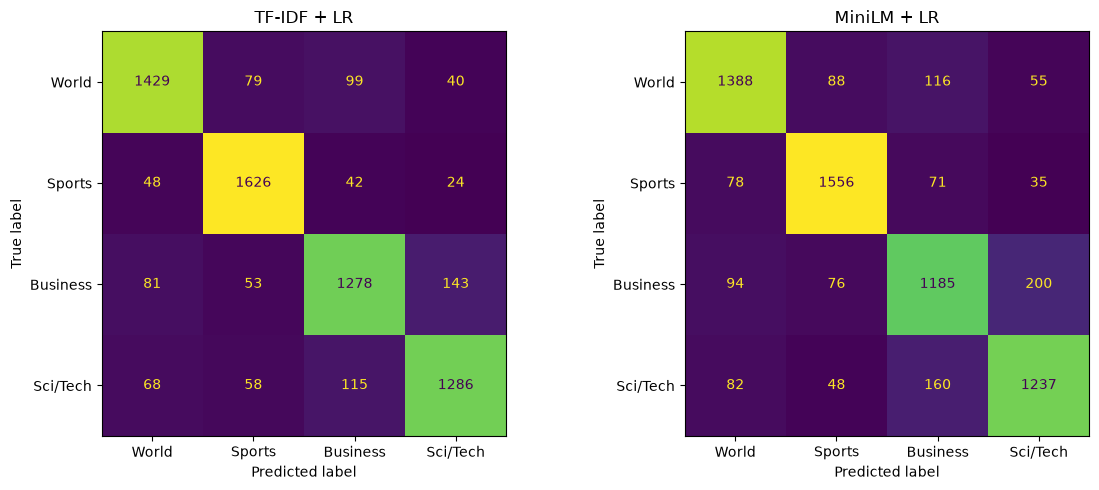

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(test["label"], pred_tfidf, display_labels=LABELS, ax=axes[0], colorbar=False)
axes[0].set_title("TF-IDF + LR")
ConfusionMatrixDisplay.from_predictions(test["label"], pred_emb, display_labels=LABELS, ax=axes[1], colorbar=False)
axes[1].set_title("MiniLM + LR")
plt.tight_layout()
plt.savefig("results/confusion_matrices.png", dpi=150)
plt.show()

### Names not seen in training

In the proposal we said we would test if the embeddings do better on company and product names that were not in the training data. We split the test headlines into ones that have a word not seen in training and ones that don't.

In [14]:
train_words = set(" ".join(train["key"]).split())
has_new_word = test["key"].apply(lambda t: any(w not in train_words for w in t.split()))
bs = test["label"].isin([B, S])

rows = []
for name, mask in [("no new word", ~has_new_word), ("has new word", has_new_word)]:
    rows.append({"group": name, "headlines": mask.sum(),
                 "TF-IDF acc": accuracy_score(test["label"][mask], pred_tfidf[mask]),
                 "MiniLM acc": accuracy_score(test["label"][mask], pred_emb[mask]),
                 "TF-IDF acc (Business/Sci-Tech)": accuracy_score(test["label"][mask & bs], pred_tfidf[mask & bs]),
                 "MiniLM acc (Business/Sci-Tech)": accuracy_score(test["label"][mask & bs], pred_emb[mask & bs])})
pd.DataFrame(rows).round(4)

,group,headlines,TF-IDF acc,MiniLM acc,TF-IDF acc (Business/Sci-Tech),MiniLM acc (Business/Sci-Tech)
0,no new word,4967,0.8802,0.8363,0.8462,0.7892
1,has new word,1502,0.8302,0.8069,0.7846,0.7748


### Wrong predictions

In [15]:
test["TF-IDF"] = [LABELS[p] for p in pred_tfidf]
test["MiniLM"] = [LABELS[p] for p in pred_emb]
test["true"] = [LABELS[p] for p in test["label"]]
wrong = test[bs & ((pred_tfidf != test["label"]) | (pred_emb != test["label"]))]
print("Business/Sci-Tech headlines where at least one model is wrong:", len(wrong))
wrong[["text", "true", "TF-IDF", "MiniLM"]].sample(15, random_state=SEED)

Business/Sci-Tech headlines where at least one model is wrong: 817


,text,true,TF-IDF,MiniLM
1583,Keep It in the Family,Business,Sports,Business
3872,Broadcom taps ex-Philips executive as CEO,Sci/Tech,Sci/Tech,Business
1913,Number of Kids on Antidepressants Drops Dramat...,Sci/Tech,Business,Sci/Tech
4475,Start-ups are discovering they might have to w...,Business,Sports,Sci/Tech
4472,Closing the giving gap,Business,Business,Sports
6340,A Distraction as a Deadline Approaches,Sci/Tech,Sports,Sci/Tech
1595,Nortel lowers expectations,Sci/Tech,Business,Business
5794,NTL to shed broadcasting arm,Business,Business,Sci/Tech
3520,Opel workers abandon wildcat strikes,Business,Business,World
2072,Locusts Encroach on West African Rice-Growing ...,Sci/Tech,World,Sci/Tech


In [16]:
examples = [3464, 2815, 2201]
test.loc[examples, ["text", "true", "TF-IDF", "MiniLM"]]

,text,true,TF-IDF,MiniLM
3464,"Greenspan: Debt, home prices not dangerous",Sci/Tech,Business,Business
2815,34 tech firms sued for alleged LCD patent theft,Business,Sci/Tech,Sci/Tech
2201,Before the Bell - ESS Technology drops 4.4 pct,Business,Business,Sci/Tech


**Explaining three wrong predictions**

1. *"Greenspan: Debt, home prices not dangerous"*: true label Sci/Tech, both models say Business. The headline is about the economy (debt, home prices, the Federal Reserve chairman), so Business looks right to us. We think the label in the dataset is wrong. Not every error is the model's fault.

2. *"34 tech firms sued for alleged LCD patent theft"*: true label Business, both models say Sci/Tech. The story is a lawsuit, but words like "tech", "LCD" and "patent" appear a lot in Sci/Tech headlines. This is the Business / Sci/Tech overlap we expected in the proposal: the headline is about a tech company, but the event is business news.

3. *"Before the Bell - ESS Technology drops 4.4 pct"*: true label Business. TF-IDF gets it right because "Before the Bell" and "pct" show up in many stock market headlines in the training data. MiniLM says Sci/Tech. Its embedding is pulled towards technology by the company name "ESS Technology", and the logistic regression cannot pick out the stock market words.

**Answer to our question:** No. With only the headline, MiniLM + logistic regression separates Business and Sci/Tech worse than TF-IDF. It has lower F1 for both classes and more Business <-> Sci/Tech confusions. On headlines with words never seen in training, the gap gets much smaller, so the pretrained model helps a bit with new names, but not enough to win.


### Our own headlines

Each member wrote two headlines. These are not part of the test results.

In [17]:
own = pd.DataFrame([
    ("Team leader", "Central bank raises interest rates for the third time this year", "Business"),
    ("Team leader", "Astronomers detect water vapour on a planet orbiting a nearby star", "Sci/Tech"),
    ("Member 2", "Striker scores twice as underdogs reach the cup final", "Sports"),
    ("Member 2", "Chip maker's profit triples on demand for AI servers", "Business"),
    ("Member 3", "New phone app translates sign language into text in real time", "Sci/Tech"),
    ("Member 3", "Ceasefire talks resume as aid convoys cross the border", "World"),
], columns=["member", "headline", "our label"])
own["TF-IDF"] = [LABELS[p] for p in tfidf_model.predict(own["headline"])]
own["MiniLM"] = [LABELS[p] for p in emb_model.predict(encoder.encode(list(own["headline"]), normalize_embeddings=True))]
own

,member,headline,our label,TF-IDF,MiniLM
0,Team leader,Central bank raises interest rates for the thi...,Business,Business,Business
1,Team leader,Astronomers detect water vapour on a planet or...,Sci/Tech,Sci/Tech,Sci/Tech
2,Member 2,Striker scores twice as underdogs reach the cu...,Sports,Sports,Sports
3,Member 2,Chip maker's profit triples on demand for AI s...,Business,Sci/Tech,Sci/Tech
4,Member 3,New phone app translates sign language into te...,Sci/Tech,Sci/Tech,Sci/Tech
5,Member 3,Ceasefire talks resume as aid convoys cross th...,World,World,World


In [18]:
table.to_csv("results/test_results.csv")
test[["text", "true", "TF-IDF", "MiniLM"]].to_csv("results/test_predictions.csv", index=False)

## Try it

Type a headline and run the cell. It uses the saved models, so nothing is retrained (run the Setup cells first).

In [19]:
tfidf_saved = joblib.load("models/tfidf_logreg.joblib")
emb_saved = joblib.load("models/minilm_logreg.joblib")
encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)


def predict(headline):
    if not headline or not headline.strip():
        print("Please type a headline first.")
        return
    text = clean_title(headline)
    p1 = tfidf_saved.predict_proba([text])[0]
    p2 = emb_saved.predict_proba(encoder.encode([text], normalize_embeddings=True))[0]
    print("Headline:", headline)
    print(f"TF-IDF + LR: {LABELS[p1.argmax()]} ({p1.max():.0%})")
    print(f"MiniLM + LR: {LABELS[p2.argmax()]} ({p2.max():.0%})")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4232.48it/s]

In [20]:
headline = "Electric carmaker's shares slide after battery recall"  #@param {type:"string"}
predict(headline)

Headline: Electric carmaker's shares slide after battery recall
TF-IDF + LR: Business (86%)
MiniLM + LR: Business (68%)


In [21]:
predict("")

Please type a headline first.


## Sources

- Dataset: AG News, Kaggle (amananandrai/ag-news-classification-dataset), from Zhang et al. [1].
- Model: sentence-transformers/all-MiniLM-L6-v2 from Hugging Face [2, 3].
- Libraries: pandas, numpy, scikit-learn, sentence-transformers, PyTorch, matplotlib, joblib, kagglehub.
- We used an AI assistant (Claude) to help write parts of the code.

[1] X. Zhang, J. Zhao, and Y. LeCun, "Character-level convolutional networks for text classification," NeurIPS 2015.
[2] N. Reimers and I. Gurevych, "Sentence-BERT: Sentence embeddings using Siamese BERT-networks," EMNLP-IJCNLP 2019.
[3] W. Wang et al., "MiniLM: Deep self-attention distillation for task-agnostic compression of pre-trained transformers," NeurIPS 2020.